<a href="https://colab.research.google.com/github/2hard4ynot/LABORATORY-EXAM/blob/main/Inot_Laboratory_Exam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [61]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
import os

from sklearn.impute import SimpleImputer
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import precision_recall_fscore_support, accuracy_score

In [62]:
file_path = '/content/sample_data/telecom_churn.csv'
df = pd.read_csv(file_path)
display(df.head())

,state,account length,area code,phone number,international plan,voice mail plan,number vmail messages,total day minutes,total day calls,total day charge,...,total eve calls,total eve charge,total night minutes,total night calls,total night charge,total intl minutes,total intl calls,total intl charge,customer service calls,churn
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [63]:
print(df.info())
X = df.drop(columns=['phone number', 'churn'])
y = df['churn']
X = pd.get_dummies(X, drop_first=True)
if y.dtype == 'object' or y.dtype == 'bool':
    y = y.astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nTraining shape: {X_train.shape}")
print(f"Testing shape: {X_test.shape}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   state                   3333 non-null   object 
 1   account length          3333 non-null   int64  
 2   area code               3333 non-null   int64  
 3   phone number            3333 non-null   object 
 4   international plan      3333 non-null   object 
 5   voice mail plan         3333 non-null   object 
 6   number vmail messages   3333 non-null   int64  
 7   total day minutes       3333 non-null   float64
 8   total day calls         3333 non-null   int64  
 9   total day charge        3333 non-null   float64
 10  total eve minutes       3333 non-null   float64
 11  total eve calls         3333 non-null   int64  
 12  total eve charge        3333 non-null   float64
 13  total night minutes     3333 non-null   float64
 14  total night calls       3333 non-null   

In [64]:
print("=== Missing Values Check ===")
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0] if (missing_values > 0).any() else "No missing values found!")

X = df.drop(columns=['phone number', 'churn'])
y = df['churn'].astype(int)

num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()

num_imputer = SimpleImputer(strategy='median')
X[num_cols] = num_imputer.fit_transform(X[num_cols])
cat_imputer = SimpleImputer(strategy='most_frequent')
X[cat_cols] = cat_imputer.fit_transform(X[cat_cols])

X = pd.get_dummies(X, columns=cat_cols, drop_first=True)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"\nTrain-Test Split complete")
print(f"Training set shape: {X_train.shape} (Churn ratio: {y_train.mean():.4%})")
print(f"Testing set shape: {X_test.shape} (Churn ratio: {y_test.mean():.4%})")

=== Missing Values Check ===
No missing values found!

Train-Test Split complete
Training set shape: (2666, 68) (Churn ratio: 14.4786%)
Testing set shape: (667, 68) (Churn ratio: 14.5427%)


In [65]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

results = {}
for name, model in models.items():
    if name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
        predictions = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

    acc = accuracy_score(y_test, predictions)
    results[name] = acc
    print(f"{name} Accuracy: {acc:.4f}")

Logistic Regression Accuracy: 0.8636
Decision Tree Accuracy: 0.8996
Random Forest Accuracy: 0.9325


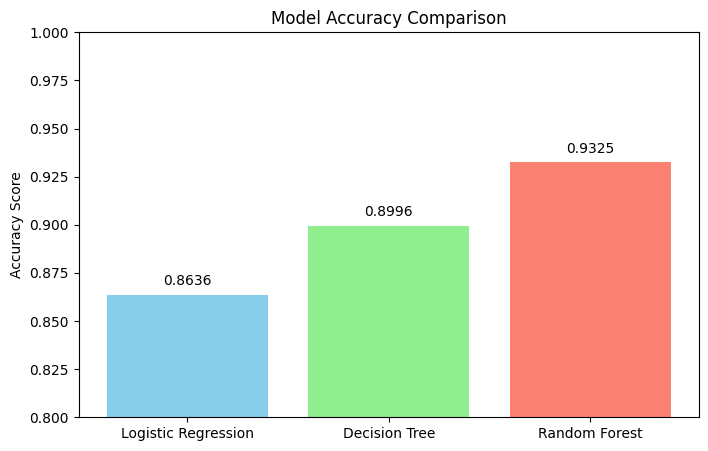

In [66]:
plt.figure(figsize=(8, 5))
plt.bar(results.keys(), results.values(), color=['skyblue', 'lightgreen', 'salmon'])
plt.ylabel('Accuracy Score')
plt.title('Model Accuracy Comparison')
plt.ylim(0.8, 1.0)
for index, value in enumerate(results.values()):
    plt.text(index, value + 0.005, f"{value:.4f}", ha='center')
plt.show()

In [67]:
from sklearn.metrics import classification_report

for name, model in models.items():
    print(f"==={name} Classification Report===")
    if name == "Logistic Regression":
        preds = model.predict(X_test_scaled)
    else:
        preds = model.predict(X_test)

    print(classification_report(y_test, preds))
    print("\n" + "="*40 + "\n")

===Logistic Regression Classification Report===
              precision    recall  f1-score   support

           0       0.89      0.96      0.92       570
           1       0.57      0.27      0.36        97

    accuracy                           0.86       667
   macro avg       0.73      0.62      0.64       667
weighted avg       0.84      0.86      0.84       667



===Decision Tree Classification Report===
              precision    recall  f1-score   support

           0       0.94      0.94      0.94       570
           1       0.66      0.64      0.65        97

    accuracy                           0.90       667
   macro avg       0.80      0.79      0.80       667
weighted avg       0.90      0.90      0.90       667



===Random Forest Classification Report===
              precision    recall  f1-score   support

           0       0.93      0.99      0.96       570
           1       0.92      0.59      0.72        97

    accuracy                           0.93   

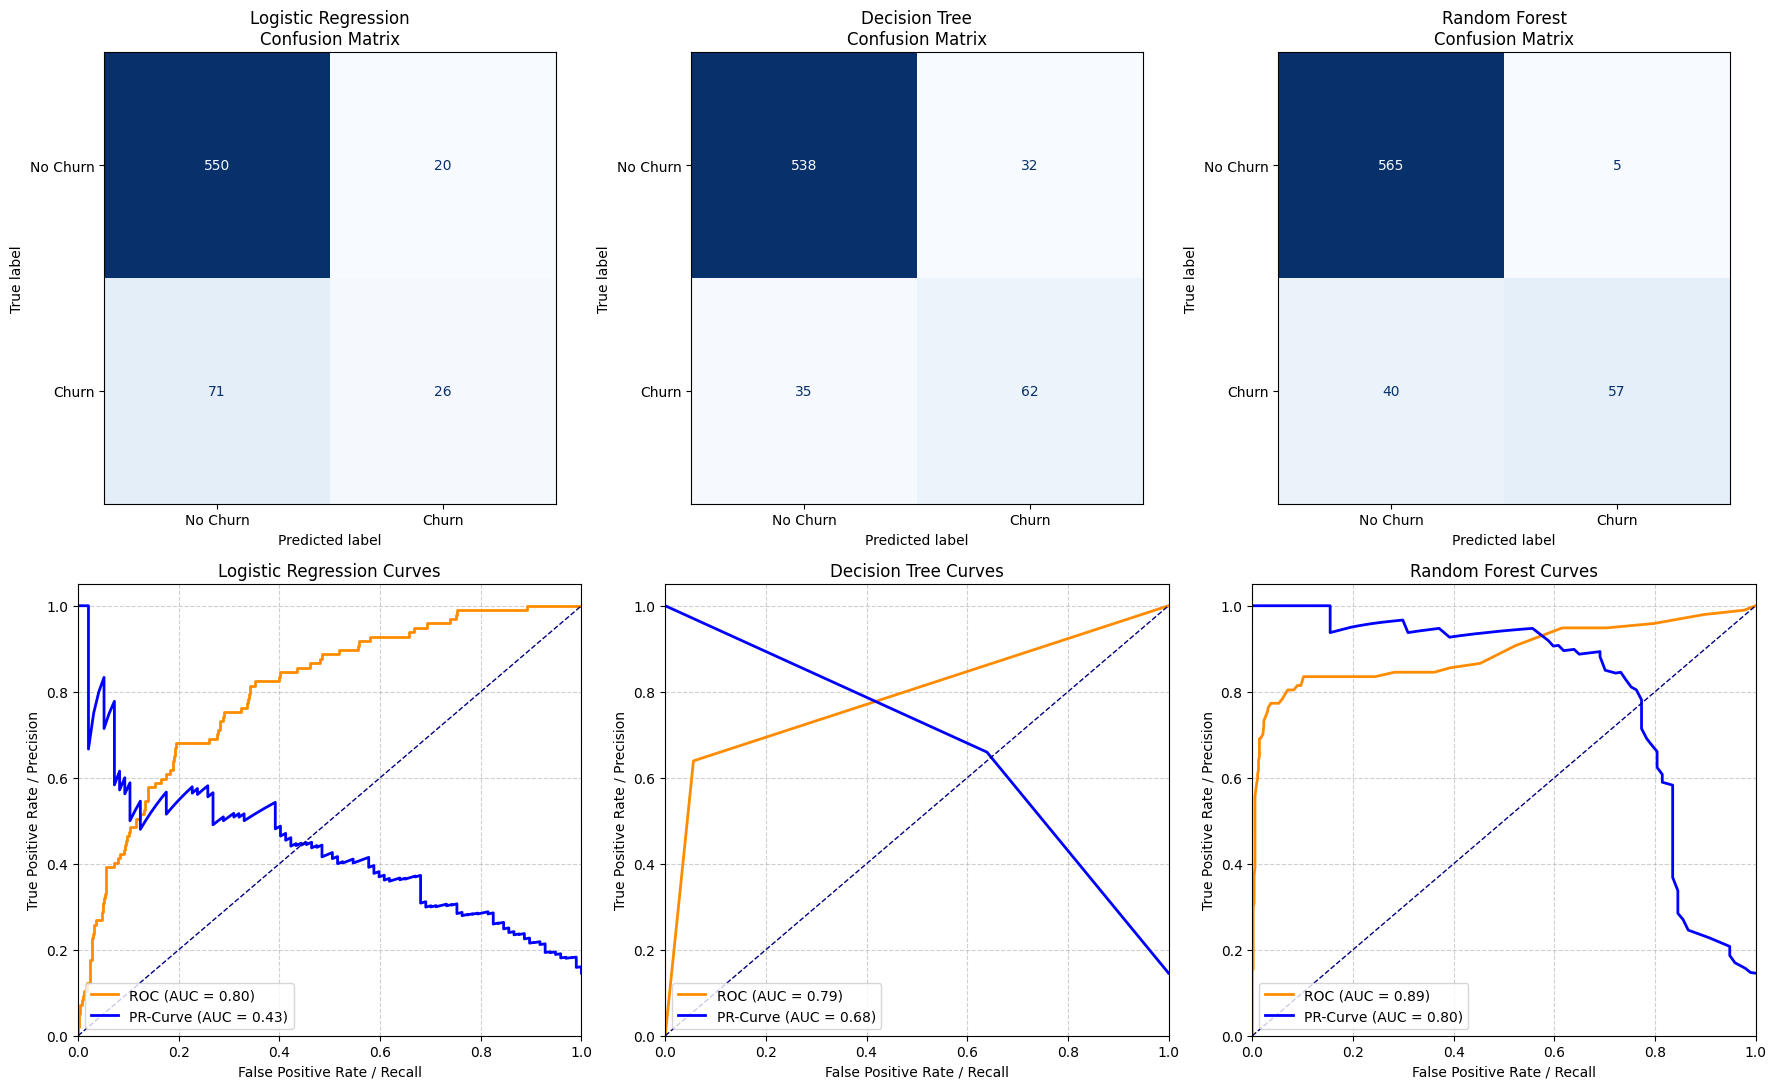

In [68]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 3, figsize=(18, 11))

for i, (name, model) in enumerate(models.items()):
    if name == "Logistic Regression":
        probs = model.predict_proba(X_test_scaled)[:, 1]
        preds = model.predict(X_test_scaled)
    else:
        probs = model.predict_proba(X_test)[:, 1]
        preds = model.predict(X_test)

    cm = confusion_matrix(y_test, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn', 'Churn'])
    disp.plot(ax=axes[0, i], cmap='Blues', colorbar=False)
    axes[0, i].set_title(f'{name}\nConfusion Matrix')

    fpr, tpr, _ = roc_curve(y_test, probs)
    roc_auc = auc(fpr, tpr)

    precision_vals, recall_vals, _ = precision_recall_curve(y_test, probs)
    pr_auc = auc(recall_vals, precision_vals)

    axes[1, i].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {roc_auc:.2f})')
    axes[1, i].plot(recall_vals, precision_vals, color='blue', lw=2, label=f'PR-Curve (AUC = {pr_auc:.2f})')
    axes[1, i].plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--')
    axes[1, i].set_xlim([0.0, 1.0])
    axes[1, i].set_ylim([0.0, 1.05])
    axes[1, i].set_xlabel('False Positive Rate / Recall')
    axes[1, i].set_ylabel('True Positive Rate / Precision')
    axes[1, i].set_title(f'{name} Curves')
    axes[1, i].legend(loc="lower left")
    axes[1, i].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [69]:
summary_data = []

for name, model in models.items():
    if name == "Logistic Regression":
        preds = model.predict(X_test_scaled)
    else:
        preds = model.predict(X_test)

    acc = accuracy_score(y_test, preds)
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, preds, average='binary', pos_label=1)

    summary_data.append({
        'Model': name,
        'Accuracy': acc,
        'Precision (Churn)': precision,
        'Recall (Churn)': recall,
        'F1-Score (Churn)': f1
    })

summary_df = pd.DataFrame(summary_data)
comparison_df = summary_df.set_index('Model').T
comparison_df.columns.name = None
comparison_df.index.name = 'Metric'

comparison_df = comparison_df.rename(index={
    'Accuracy': 'accuracy',
    'Precision (Churn)': 'precision',
    'Recall (Churn)': 'recall',
    'F1-Score (Churn)': 'f1 score'
})

display(comparison_df)

,Logistic Regression,Decision Tree,Random Forest
Metric,,,
accuracy,0.863568,0.899550,0.932534
precision,0.565217,0.659574,0.919355
recall,0.268041,0.639175,0.587629
f1 score,0.363636,0.649215,0.716981
